# Monkeypox Classification Using CART

**Machine Learning | Classification | Python | Jupyter Notebook**

## Objective
Implement a CART (Classification and Regression Trees) classification workflow using a synthetic Monkeypox-related educational dataset with 600 records.

The notebook follows the structure of the supplied Student Placement Prediction CART notebook and extends it to include the full manual Gini calculation task.

### Learning outcomes
1. Inspect the dataset and identify unique values in every input feature.
2. Count the `Yes` and `No` target records and total observations.
3. Identify the target variable and input features.
4. Calculate Parent Gini impurity.
5. Generate every unique, non-redundant binary split for each categorical feature.
6. Calculate Left Gini, Right Gini, Weighted Child Gini, and Gini Reduction for every split.
7. Identify the best root split.
8. Train and evaluate a CART classifier using a train-test split.
9. Visualize the tree and feature importance.

## 1. Import the required libraries

Run this cell first. If a library is missing, install it using `pip install pandas numpy matplotlib scikit-learn`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools

from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Generate the synthetic Monkeypox-related dataset

We create 600 synthetic observations with categorical input features. The target `Monkeypox_Status` has two classes: `Yes` and `No`.

Features:
- Fever
- Rash
- Lymphadenopathy
- Muscle_Aches
- Headache
- Exposure_History
- Travel_History
- Rash_Type
- Lesion_Location
- Symptom_Severity


In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n_records = 600

fever = rng.choice(["Yes", "No"], n_records, p=[0.42, 0.58])
rash = rng.choice(["Yes", "No"], n_records, p=[0.68, 0.32])
lymphadenopathy = rng.choice(["Yes", "No"], n_records, p=[0.38, 0.62])
muscle_aches = rng.choice(["Yes", "No"], n_records, p=[0.48, 0.52])
headache = rng.choice(["Yes", "No"], n_records, p=[0.45, 0.55])
exposure_history = rng.choice(["Yes", "No"], n_records, p=[0.24, 0.76])
travel_history = rng.choice(["Yes", "No"], n_records, p=[0.18, 0.82])

rash_type = []
lesion_location = []
symptom_severity = []

for rash_value in rash:
    if rash_value == "No":
        rash_type.append("None")
        lesion_location.append("None")
        symptom_severity.append("None")
    else:
        rash_type.append(
            rng.choice(["Vesicular", "Pustular", "Maculopapular"],
                       p=[0.48, 0.32, 0.20])
        )
        lesion_location.append(
            rng.choice(["Face", "Hands", "Trunk", "Multiple"],
                       p=[0.20, 0.25, 0.35, 0.20])
        )
        symptom_severity.append(
            rng.choice(["Mild", "Moderate", "Severe"],
                       p=[0.25, 0.45, 0.30])
        )

# Artificial score used only to generate a synthetic classroom target.
score = (
    (fever == "Yes") * 0.60
    + (rash == "Yes") * 1.10
    + (lymphadenopathy == "Yes") * 1.00
    + (muscle_aches == "Yes") * 0.25
    + (headache == "Yes") * 0.20
    + (exposure_history == "Yes") * 1.35
    + (travel_history == "Yes") * 0.25
    + (np.array(rash_type) != "None") * 0.25
    + (np.array(lesion_location) != "None") * 0.10
    + (np.array(symptom_severity) == "Severe") * 0.20
)

# Convert the artificial score to probabilities and generate Yes/No labels.
probability = 1 / (1 + np.exp(-(-3.40 + score)))
synthetic_target = rng.binomial(1, probability, n_records)
monkeypox_status = np.where(synthetic_target == 1, "Yes", "No")

df = pd.DataFrame({
    "Fever": fever,
    "Rash": rash,
    "Lymphadenopathy": lymphadenopathy,
    "Muscle_Aches": muscle_aches,
    "Headache": headache,
    "Exposure_History": exposure_history,
    "Travel_History": travel_history,
    "Rash_Type": rash_type,
    "Lesion_Location": lesion_location,
    "Symptom_Severity": symptom_severity,
    "Monkeypox_Status": monkeypox_status
})

# Save the generated dataset beside the notebook.
df.to_csv("monkeypox_synthetic_cart_dataset.csv", index=False)

print("Synthetic dataset generated and saved.")
print("Dataset shape:", df.shape)
display(df.head(10))

Synthetic dataset generated and saved.
Dataset shape: (600, 11)


,Fever,Rash,Lymphadenopathy,Muscle_Aches,Headache,Exposure_History,Travel_History,Rash_Type,Lesion_Location,Symptom_Severity,Monkeypox_Status
0,No,Yes,No,No,No,No,No,Vesicular,Multiple,Mild,No
1,No,No,No,No,No,No,Yes,None,None,None,No
2,No,No,No,Yes,No,No,No,None,None,None,No
3,No,No,No,No,No,No,No,None,None,None,No
4,Yes,No,Yes,No,No,Yes,No,None,None,None,No
5,No,No,Yes,No,Yes,No,Yes,None,None,None,No
6,No,No,No,Yes,No,No,Yes,None,None,None,No
7,No,Yes,No,Yes,Yes,Yes,No,Pustular,Trunk,Severe,Yes
8,Yes,No,Yes,Yes,Yes,Yes,No,None,None,None,Yes
9,No,Yes,No,Yes,No,No,No,Vesicular,Face,Moderate,No


## 3. Understand the dataset

Inspect column types, missing values, duplicate records, and descriptive summaries.

In [3]:
print("Dataset information:")
df.info()

print("\\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\\nDuplicate rows:", df.duplicated().sum())

print("\\nStatistical summary:")
display(df.describe(include="all").T)

print("\\nTotal records:", len(df))
print("Total input columns:", df.shape[1] - 1)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Fever             600 non-null    str  
 1   Rash              600 non-null    str  
 2   Lymphadenopathy   600 non-null    str  
 3   Muscle_Aches      600 non-null    str  
 4   Headache          600 non-null    str  
 5   Exposure_History  600 non-null    str  
 6   Travel_History    600 non-null    str  
 7   Rash_Type         600 non-null    str  
 8   Lesion_Location   600 non-null    str  
 9   Symptom_Severity  600 non-null    str  
 10  Monkeypox_Status  600 non-null    str  
dtypes: str(11)
memory usage: 51.7 KB
\nMissing values in each column:


,Missing Values
Fever,0
Rash,0
Lymphadenopathy,0
Muscle_Aches,0
Headache,0
Exposure_History,0
Travel_History,0
Rash_Type,0
Lesion_Location,0
Symptom_Severity,0


\nDuplicate rows: 188
\nStatistical summary:


,count,unique,top,freq
Fever,600,2,No,350
Rash,600,2,Yes,400
Lymphadenopathy,600,2,No,376
Muscle_Aches,600,2,Yes,308
Headache,600,2,No,345
Exposure_History,600,2,No,460
Travel_History,600,2,No,497
Rash_Type,600,4,Vesicular,216
Lesion_Location,600,5,None,200
Symptom_Severity,600,4,None,200


\nTotal records: 600
Total input columns: 10


## 4. Check and clean the data

The generated dataset should have no missing values. This section checks the data and removes exact duplicate rows if any exist. We retain the target column and all input features.

In [4]:
# Repeated rows are possible because the data is categorical and synthetically sampled.
# They represent repeated observations, so we report them but do not delete them.
duplicate_count = int(df.duplicated().sum())
print("Repeated feature/target patterns (retained):", duplicate_count)

target_column = "Monkeypox_Status"

if target_column not in df.columns:
    raise ValueError(f"Required target column '{target_column}' is missing.")

df = df.dropna(subset=[target_column]).copy()

expected_labels = {"Yes", "No"}
actual_labels = set(df[target_column].unique())
if not actual_labels.issubset(expected_labels):
    raise ValueError(f"Unexpected target labels: {actual_labels}")

print("Shape after target validation:", df.shape)
print("Target categories:", sorted(df[target_column].unique()))
print("Missing values after validation:", int(df.isnull().sum().sum()))

Repeated feature/target patterns (retained): 188
Shape after target validation: (600, 11)
Target categories: ['No', 'Yes']
Missing values after validation: 0


## 5. Exploratory Data Analysis (EDA)

Visualize the target class distribution and the distributions of selected categorical features.

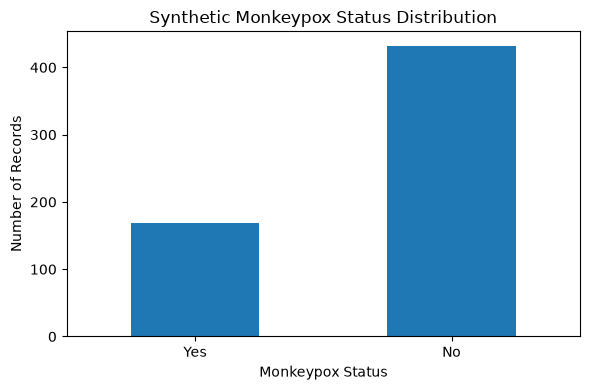

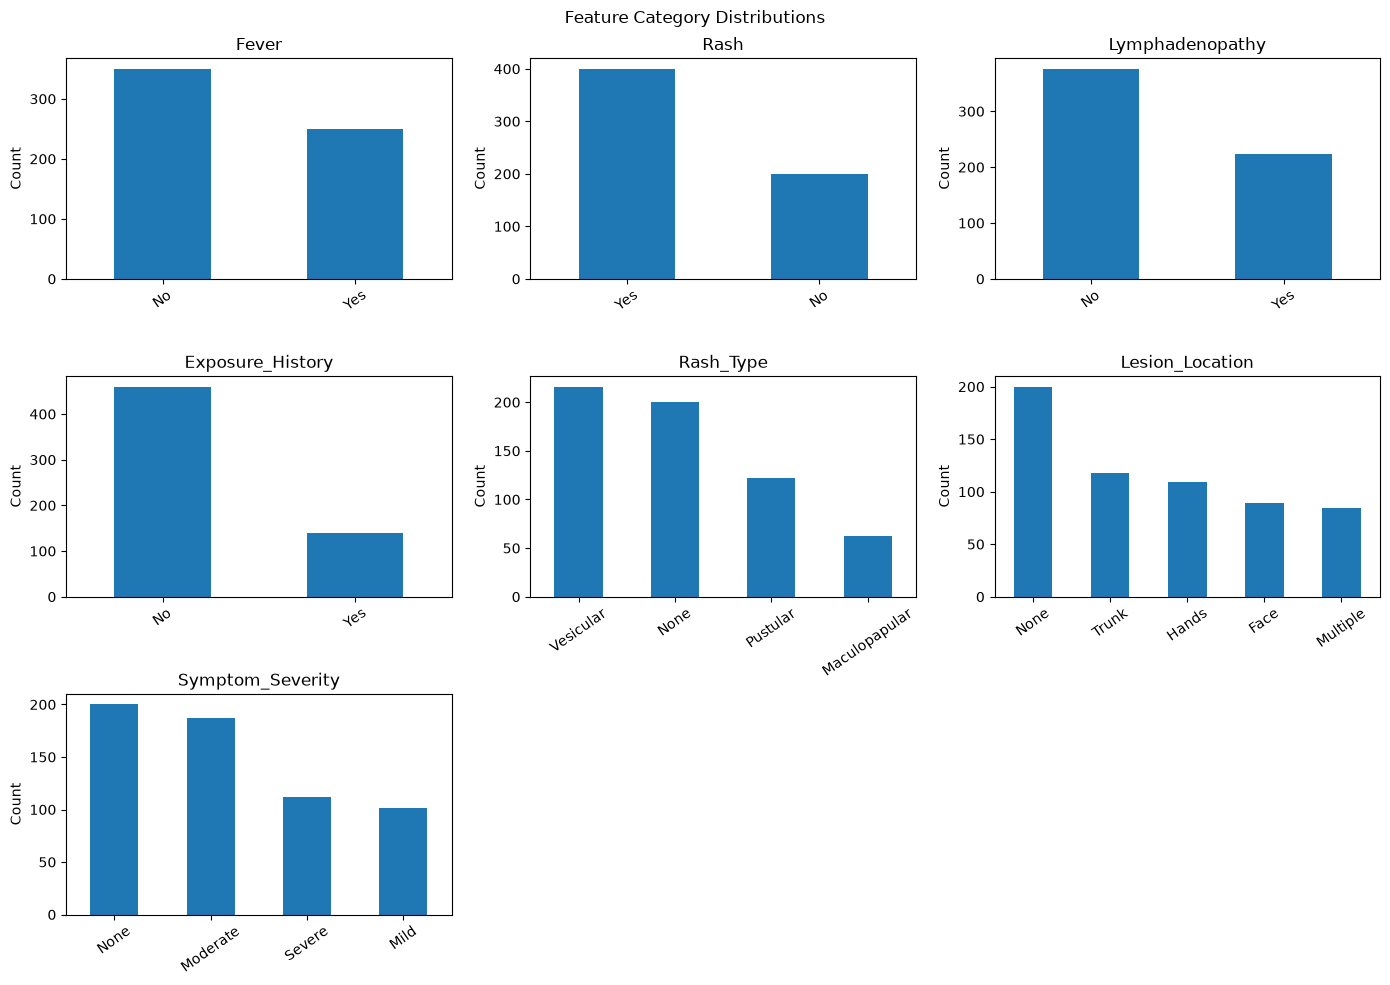

In [5]:
# Target class distribution
target_counts = df[target_column].value_counts().reindex(["Yes", "No"], fill_value=0)

plt.figure(figsize=(6, 4))
target_counts.plot(kind="bar")
plt.title("Synthetic Monkeypox Status Distribution")
plt.xlabel("Monkeypox Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Frequency charts for selected features
eda_features = ["Fever", "Rash", "Lymphadenopathy", "Exposure_History",
                "Rash_Type", "Lesion_Location", "Symptom_Severity"]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, feature in zip(axes.flat, eda_features):
    df[feature].value_counts().plot(kind="bar", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=35)

for ax in axes.flat[len(eda_features):]:
    ax.axis("off")

plt.suptitle("Feature Category Distributions")
plt.tight_layout()
plt.show()

## 6. Identify target variable, input features, unique values, and class counts

The target variable is `Monkeypox_Status`. All other columns are input features.

This section explicitly completes the first student task:
- Identify unique values in every input feature.
- Count Yes and No records.
- Count total records.
- Identify the target variable.
- Identify input features.

In [6]:
target_column = "Monkeypox_Status"
feature_columns = [column for column in df.columns if column != target_column]

print("Target variable:", target_column)
print("Input features:", feature_columns)
print("Number of input features:", len(feature_columns))
print("Total records:", len(df))

# Target counts
target_counts = df[target_column].value_counts()
yes_count = int(target_counts.get("Yes", 0))
no_count = int(target_counts.get("No", 0))

print("\\nTarget class counts:")
print("Yes records:", yes_count)
print("No records:", no_count)
print("Total Yes + No:", yes_count + no_count)

display(target_counts.rename_axis("Monkeypox_Status").reset_index(name="Count"))

# Unique values in each input feature
unique_rows = []
for feature in feature_columns:
    values = sorted(df[feature].dropna().unique().tolist())
    unique_rows.append({
        "Feature": feature,
        "Unique Values": values,
        "Number of Unique Values": len(values)
    })

unique_values_df = pd.DataFrame(unique_rows)
display(unique_values_df)

Target variable: Monkeypox_Status
Input features: ['Fever', 'Rash', 'Lymphadenopathy', 'Muscle_Aches', 'Headache', 'Exposure_History', 'Travel_History', 'Rash_Type', 'Lesion_Location', 'Symptom_Severity']
Number of input features: 10
Total records: 600
\nTarget class counts:
Yes records: 168
No records: 432
Total Yes + No: 600


,Monkeypox_Status,Count
0,No,432
1,Yes,168


,Feature,Unique Values,Number of Unique Values
0,Fever,"[No, Yes]",2
1,Rash,"[No, Yes]",2
2,Lymphadenopathy,"[No, Yes]",2
3,Muscle_Aches,"[No, Yes]",2
4,Headache,"[No, Yes]",2
5,Exposure_History,"[No, Yes]",2
6,Travel_History,"[No, Yes]",2
7,Rash_Type,"[Maculopapular, None, Pustular, Vesicular]",4
8,Lesion_Location,"[Face, Hands, Multiple, None, Trunk]",5
9,Symptom_Severity,"[Mild, Moderate, None, Severe]",4


## 7. Calculate Parent Gini impurity

Gini impurity measures the impurity of a node.

\[
Gini = 1 - \sum_{i=1}^{k} p_i^2
\]

For the binary target:

\[
Gini(Parent) = 1 - P(Yes)^2 - P(No)^2
\]

where `P(Yes) = Yes count / Total records` and `P(No) = No count / Total records`.

In [7]:
def gini_impurity(target_values):
    """Return Gini impurity for a target Series or list."""
    values = pd.Series(target_values)
    if len(values) == 0:
        return 0.0
    probabilities = values.value_counts(normalize=True)
    return float(1 - (probabilities ** 2).sum())

total_records = len(df)
p_yes = yes_count / total_records
p_no = no_count / total_records
parent_gini = gini_impurity(df[target_column])

print(f"P(Yes) = {yes_count}/{total_records} = {p_yes:.6f}")
print(f"P(No)  = {no_count}/{total_records} = {p_no:.6f}")
print(f"Parent Gini = 1 - ({p_yes:.6f})^2 - ({p_no:.6f})^2")
print(f"Parent Gini impurity = {parent_gini:.6f}")

P(Yes) = 168/600 = 0.280000
P(No)  = 432/600 = 0.720000
Parent Gini = 1 - (0.280000)^2 - (0.720000)^2
Parent Gini impurity = 0.403200


## 8. Identify all possible unique binary splits

CART creates two child nodes at each decision. For a categorical feature with `k` unique categories, the number of unique non-redundant binary partitions is:

\[
2^{k-1}-1
\]

A split and its complement are the same partition in reverse order, so we evaluate only one of them.

For example, `{A}` vs `{B, C}` is the same partition as `{B, C}` vs `{A}`.

The following code generates every possible non-empty binary partition for each categorical input feature.

In [8]:
def generate_binary_splits(values):
    """Generate unique non-empty binary partitions of categorical values."""
    categories = sorted(pd.Series(values).dropna().unique().tolist())

    if len(categories) < 2:
        return []

    splits = []
    first_category = categories[0]
    remaining_categories = categories[1:]

    # Fix the first category in the left group to avoid complementary duplicates.
    for r in range(len(remaining_categories) + 1):
        for combination in itertools.combinations(remaining_categories, r):
            left_values = [first_category] + list(combination)
            right_values = [
                category for category in categories
                if category not in left_values
            ]

            if right_values:
                splits.append((left_values, right_values))

    return splits


candidate_splits = []
split_counts = []

for feature in feature_columns:
    feature_splits = generate_binary_splits(df[feature])
    split_counts.append({
        "Feature": feature,
        "Unique Categories": df[feature].nunique(),
        "Possible Unique Binary Splits": len(feature_splits),
        "Formula Count": 2 ** (df[feature].nunique() - 1) - 1
    })

    for left_values, right_values in feature_splits:
        candidate_splits.append({
            "Feature": feature,
            "Left Categories": left_values,
            "Right Categories": right_values
        })

split_count_df = pd.DataFrame(split_counts)
display(split_count_df)

candidate_splits_df = pd.DataFrame(candidate_splits)
print("Total unique candidate binary splits:", len(candidate_splits_df))
display(candidate_splits_df)

,Feature,Unique Categories,Possible Unique Binary Splits,Formula Count
0,Fever,2,1,1
1,Rash,2,1,1
2,Lymphadenopathy,2,1,1
3,Muscle_Aches,2,1,1
4,Headache,2,1,1
5,Exposure_History,2,1,1
6,Travel_History,2,1,1
7,Rash_Type,4,7,7
8,Lesion_Location,5,15,15
9,Symptom_Severity,4,7,7


Total unique candidate binary splits: 36


,Feature,Left Categories,Right Categories
0,Fever,[No],[Yes]
1,Rash,[No],[Yes]
2,Lymphadenopathy,[No],[Yes]
3,Muscle_Aches,[No],[Yes]
4,Headache,[No],[Yes]
5,Exposure_History,[No],[Yes]
6,Travel_History,[No],[Yes]
7,Rash_Type,[Maculopapular],"[None, Pustular, Vesicular]"
8,Rash_Type,"[Maculopapular, None]","[Pustular, Vesicular]"
9,Rash_Type,"[Maculopapular, Pustular]","[None, Vesicular]"


## 9. Calculate Gini values for every possible split

For every candidate split, calculate:

1. Parent Gini impurity.
2. Left child Gini impurity.
3. Right child Gini impurity.
4. Weighted child Gini impurity.
5. Gini reduction.

Formulas:

\[
Gini(Left)=1-\sum_i p_{i,L}^2
\]

\[
Gini(Right)=1-\sum_i p_{i,R}^2
\]

\[
Gini_{weighted} =
\frac{N_L}{N}Gini(Left)+\frac{N_R}{N}Gini(Right)
\]

\[
GiniReduction=Gini(Parent)-Gini_{weighted}
\]

The best split has the largest Gini reduction (equivalently, the smallest weighted child Gini).

In [9]:
def calculate_split_metrics(dataframe, feature, left_values, right_values, target):
    left_mask = dataframe[feature].isin(left_values)
    left_target = dataframe.loc[left_mask, target]
    right_target = dataframe.loc[~left_mask, target]

    n_total = len(dataframe)
    n_left = len(left_target)
    n_right = len(right_target)

    parent = gini_impurity(dataframe[target])
    left_gini = gini_impurity(left_target)
    right_gini = gini_impurity(right_target)

    weighted_child_gini = (
        (n_left / n_total) * left_gini
        + (n_right / n_total) * right_gini
    )
    gini_reduction = parent - weighted_child_gini

    return {
        "Feature": feature,
        "Left Split": "{" + ", ".join(map(str, left_values)) + "}",
        "Right Split": "{" + ", ".join(map(str, right_values)) + "}",
        "Left Records": n_left,
        "Left Yes": int((left_target == "Yes").sum()),
        "Left No": int((left_target == "No").sum()),
        "Right Records": n_right,
        "Right Yes": int((right_target == "Yes").sum()),
        "Right No": int((right_target == "No").sum()),
        "Parent Gini": parent,
        "Left Gini": left_gini,
        "Right Gini": right_gini,
        "Weighted Child Gini": weighted_child_gini,
        "Gini Reduction": gini_reduction
    }


split_results = []

for candidate in candidate_splits:
    metrics = calculate_split_metrics(
        df,
        candidate["Feature"],
        candidate["Left Categories"],
        candidate["Right Categories"],
        target_column
    )
    split_results.append(metrics)

gini_results_df = pd.DataFrame(split_results)

print("Gini calculation results for every candidate binary split:")
display(gini_results_df.round(6))

print("Number of splits evaluated:", len(gini_results_df))

Gini calculation results for every candidate binary split:


,Feature,Left Split,Right Split,Left Records,Left Yes,Left No,Right Records,Right Yes,Right No,Parent Gini,Left Gini,Right Gini,Weighted Child Gini,Gini Reduction
0,Fever,{No},{Yes},350,82,268,250,86,164,0.4032,0.3588,0.4513,0.3973,0.0059
1,Rash,{No},{Yes},200,21,179,400,147,253,0.4032,0.1880,0.4649,0.3726,0.0306
2,Lymphadenopathy,{No},{Yes},376,71,305,224,97,127,0.4032,0.3063,0.4910,0.3753,0.0279
3,Muscle_Aches,{No},{Yes},292,74,218,308,94,214,0.4032,0.3784,0.4241,0.4019,0.0013
4,Headache,{No},{Yes},345,83,262,255,85,170,0.4032,0.3654,0.4444,0.3990,0.0042
5,Exposure_History,{No},{Yes},460,105,355,140,63,77,0.4032,0.3523,0.4950,0.3856,0.0176
6,Travel_History,{No},{Yes},497,134,363,103,34,69,0.4032,0.3938,0.4423,0.4022,0.0010
7,Rash_Type,{Maculopapular},"{None, Pustular, Vesicular}",62,16,46,538,152,386,0.4032,0.3829,0.4054,0.4031,0.0001
8,Rash_Type,"{Maculopapular, None}","{Pustular, Vesicular}",262,37,225,338,131,207,0.4032,0.2426,0.4747,0.3733,0.0299
9,Rash_Type,"{Maculopapular, Pustular}","{None, Vesicular}",184,61,123,416,107,309,0.4032,0.4432,0.3821,0.4009,0.0023


Number of splits evaluated: 36


## 10. Rank all candidate splits and identify the best root split

The best root split is the candidate with the maximum Gini reduction.

In [10]:
ranked_splits = gini_results_df.sort_values(
    by="Gini Reduction",
    ascending=False
).reset_index(drop=True)

ranked_splits.insert(0, "Rank", np.arange(1, len(ranked_splits) + 1))

display(ranked_splits.round(6))

best_split = ranked_splits.iloc[0]

print("BEST ROOT SPLIT")
print("Feature:", best_split["Feature"])
print("Left split:", best_split["Left Split"])
print("Right split:", best_split["Right Split"])
print(f"Parent Gini: {best_split['Parent Gini']:.6f}")
print(f"Left Gini: {best_split['Left Gini']:.6f}")
print(f"Right Gini: {best_split['Right Gini']:.6f}")
print(f"Weighted child Gini: {best_split['Weighted Child Gini']:.6f}")
print(f"Gini reduction: {best_split['Gini Reduction']:.6f}")

,Rank,Feature,Left Split,Right Split,Left Records,Left Yes,Left No,Right Records,Right Yes,Right No,Parent Gini,Left Gini,Right Gini,Weighted Child Gini,Gini Reduction
0,1,Rash,{No},{Yes},200,21,179,400,147,253,0.4032,0.1880,0.4649,0.3726,0.0306
1,2,Symptom_Severity,"{Mild, Moderate, Severe}",{None},400,147,253,200,21,179,0.4032,0.4649,0.1880,0.3726,0.0306
2,3,Lesion_Location,"{Face, Hands, Multiple, Trunk}",{None},400,147,253,200,21,179,0.4032,0.4649,0.1880,0.3726,0.0306
3,4,Rash_Type,"{Maculopapular, Pustular, Vesicular}",{None},400,147,253,200,21,179,0.4032,0.4649,0.1880,0.3726,0.0306
4,5,Rash_Type,"{Maculopapular, None}","{Pustular, Vesicular}",262,37,225,338,131,207,0.4032,0.2426,0.4747,0.3733,0.0299
5,6,Lymphadenopathy,{No},{Yes},376,71,305,224,97,127,0.4032,0.3063,0.4910,0.3753,0.0279
6,7,Lesion_Location,"{Face, Hands, Trunk}","{Multiple, None}",316,117,199,284,51,233,0.4032,0.4663,0.2947,0.3851,0.0181
7,8,Lesion_Location,"{Face, Multiple, Trunk}","{Hands, None}",291,110,181,309,58,251,0.4032,0.4702,0.3049,0.3851,0.0181
8,9,Symptom_Severity,"{Mild, Moderate}","{None, Severe}",288,109,179,312,59,253,0.4032,0.4705,0.3067,0.3853,0.0179
9,10,Exposure_History,{No},{Yes},460,105,355,140,63,77,0.4032,0.3523,0.4950,0.3856,0.0176


BEST ROOT SPLIT
Feature: Rash
Left split: {No}
Right split: {Yes}
Parent Gini: 0.403200
Left Gini: 0.187950
Right Gini: 0.464888
Weighted child Gini: 0.372575
Gini reduction: 0.030625


## 11. Visualize the Gini reduction by feature

This chart displays the maximum Gini reduction achieved by each feature among its candidate binary splits. It is a comparison of candidate root splits, not a model-wide feature importance chart.

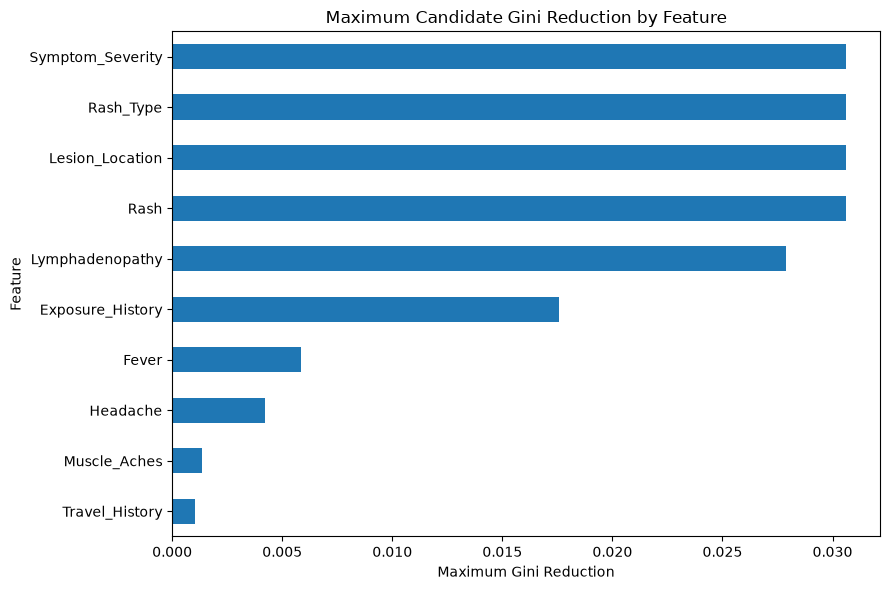

In [11]:
best_by_feature = (
    gini_results_df.groupby("Feature")["Gini Reduction"]
    .max()
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 6))
best_by_feature.plot(kind="barh")
plt.title("Maximum Candidate Gini Reduction by Feature")
plt.xlabel("Maximum Gini Reduction")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 12. Prepare the data for Scikit-learn CART

Scikit-learn's `DecisionTreeClassifier` requires numerical input. We use one-hot encoding for categorical features.



In [12]:
X = df[feature_columns].copy()
y = df[target_column].map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError("Unexpected target labels found.")

categorical_columns = X.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ],
    remainder="drop"
)

print("Input feature columns:", feature_columns)
print("Target mapping: 0 = No, 1 = Yes")
print("X shape:", X.shape)
print("y shape:", y.shape)

Input feature columns: ['Fever', 'Rash', 'Lymphadenopathy', 'Muscle_Aches', 'Headache', 'Exposure_History', 'Travel_History', 'Rash_Type', 'Lesion_Location', 'Symptom_Severity']
Target mapping: 0 = No, 1 = Yes
X shape: (600, 10)
y shape: (600,)


## 13. Split the data into training and testing sets

We use an 80:20 split. Stratification preserves the approximate Yes/No class proportions in both sets.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\\nTraining target distribution:")
display(y_train.value_counts().rename(index={0: "No", 1: "Yes"}).to_frame("Count"))

print("\\nTesting target distribution:")
display(y_test.value_counts().rename(index={0: "No", 1: "Yes"}).to_frame("Count"))

Training records: 480
Testing records: 120
\nTraining target distribution:


,Count
Monkeypox_Status,
No,346
Yes,134


\nTesting target distribution:


,Count
Monkeypox_Status,
No,86
Yes,34


## 14. Train the CART classification model

`criterion="gini"` selects Gini impurity for split quality. `max_depth`, `min_samples_split`, and `min_samples_leaf` limit tree complexity and can help control overfitting.

In [14]:
cart_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_split=12,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    ))
])

cart_model.fit(X_train, y_train)

print("CART model trained successfully.")

CART model trained successfully.


## 15. Make predictions

The model predicts the target class for records it did not see during training.

In [15]:
y_pred = cart_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.map({0: "No", 1: "Yes"}).values,
    "Predicted": pd.Series(y_pred, index=y_test.index).map(
        {0: "No", 1: "Yes"}
    ).values
})

display(results.head(15))

,Actual,Predicted
0,No,No
1,Yes,No
2,Yes,No
3,Yes,No
4,No,No
5,No,No
6,Yes,No
7,Yes,Yes
8,Yes,No
9,No,No


## 16. Evaluate the CART model

- **Accuracy:** Fraction of all predictions that are correct.
- **Precision:** Of records predicted `Yes`, how many were actually `Yes`.
- **Recall:** Of actual `Yes` records, how many were identified.
- **F1-score:** Harmonic mean of precision and recall.

These metrics evaluate this synthetic educational dataset only.

In [16]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics.round(4))

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.6667
1,Precision,0.3125
2,Recall,0.1471
3,F1-score,0.2000


Classification Report:
              precision    recall  f1-score   support

          No       0.72      0.87      0.79        86
         Yes       0.31      0.15      0.20        34

    accuracy                           0.67       120
   macro avg       0.52      0.51      0.49       120
weighted avg       0.61      0.67      0.62       120



## 17. Confusion matrix

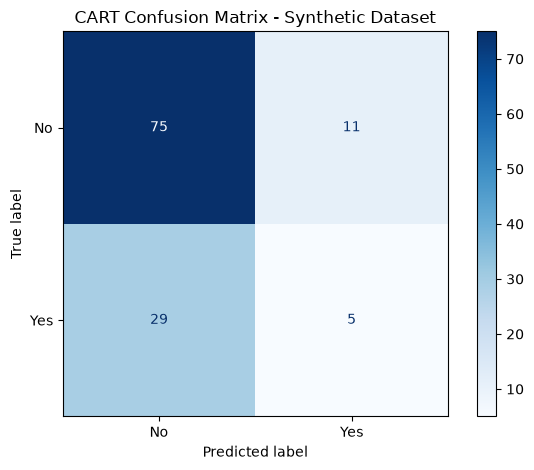

Confusion matrix layout (rows = actual, columns = predicted):
[[75 11]
 [29  5]]


In [17]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("CART Confusion Matrix - Synthetic Dataset")
plt.tight_layout()
plt.show()

print("Confusion matrix layout (rows = actual, columns = predicted):")
print(cm)

## 18. Visualize the CART decision tree

The one-hot encoder expands each original categorical feature into indicator columns. The tree below uses those encoded columns.

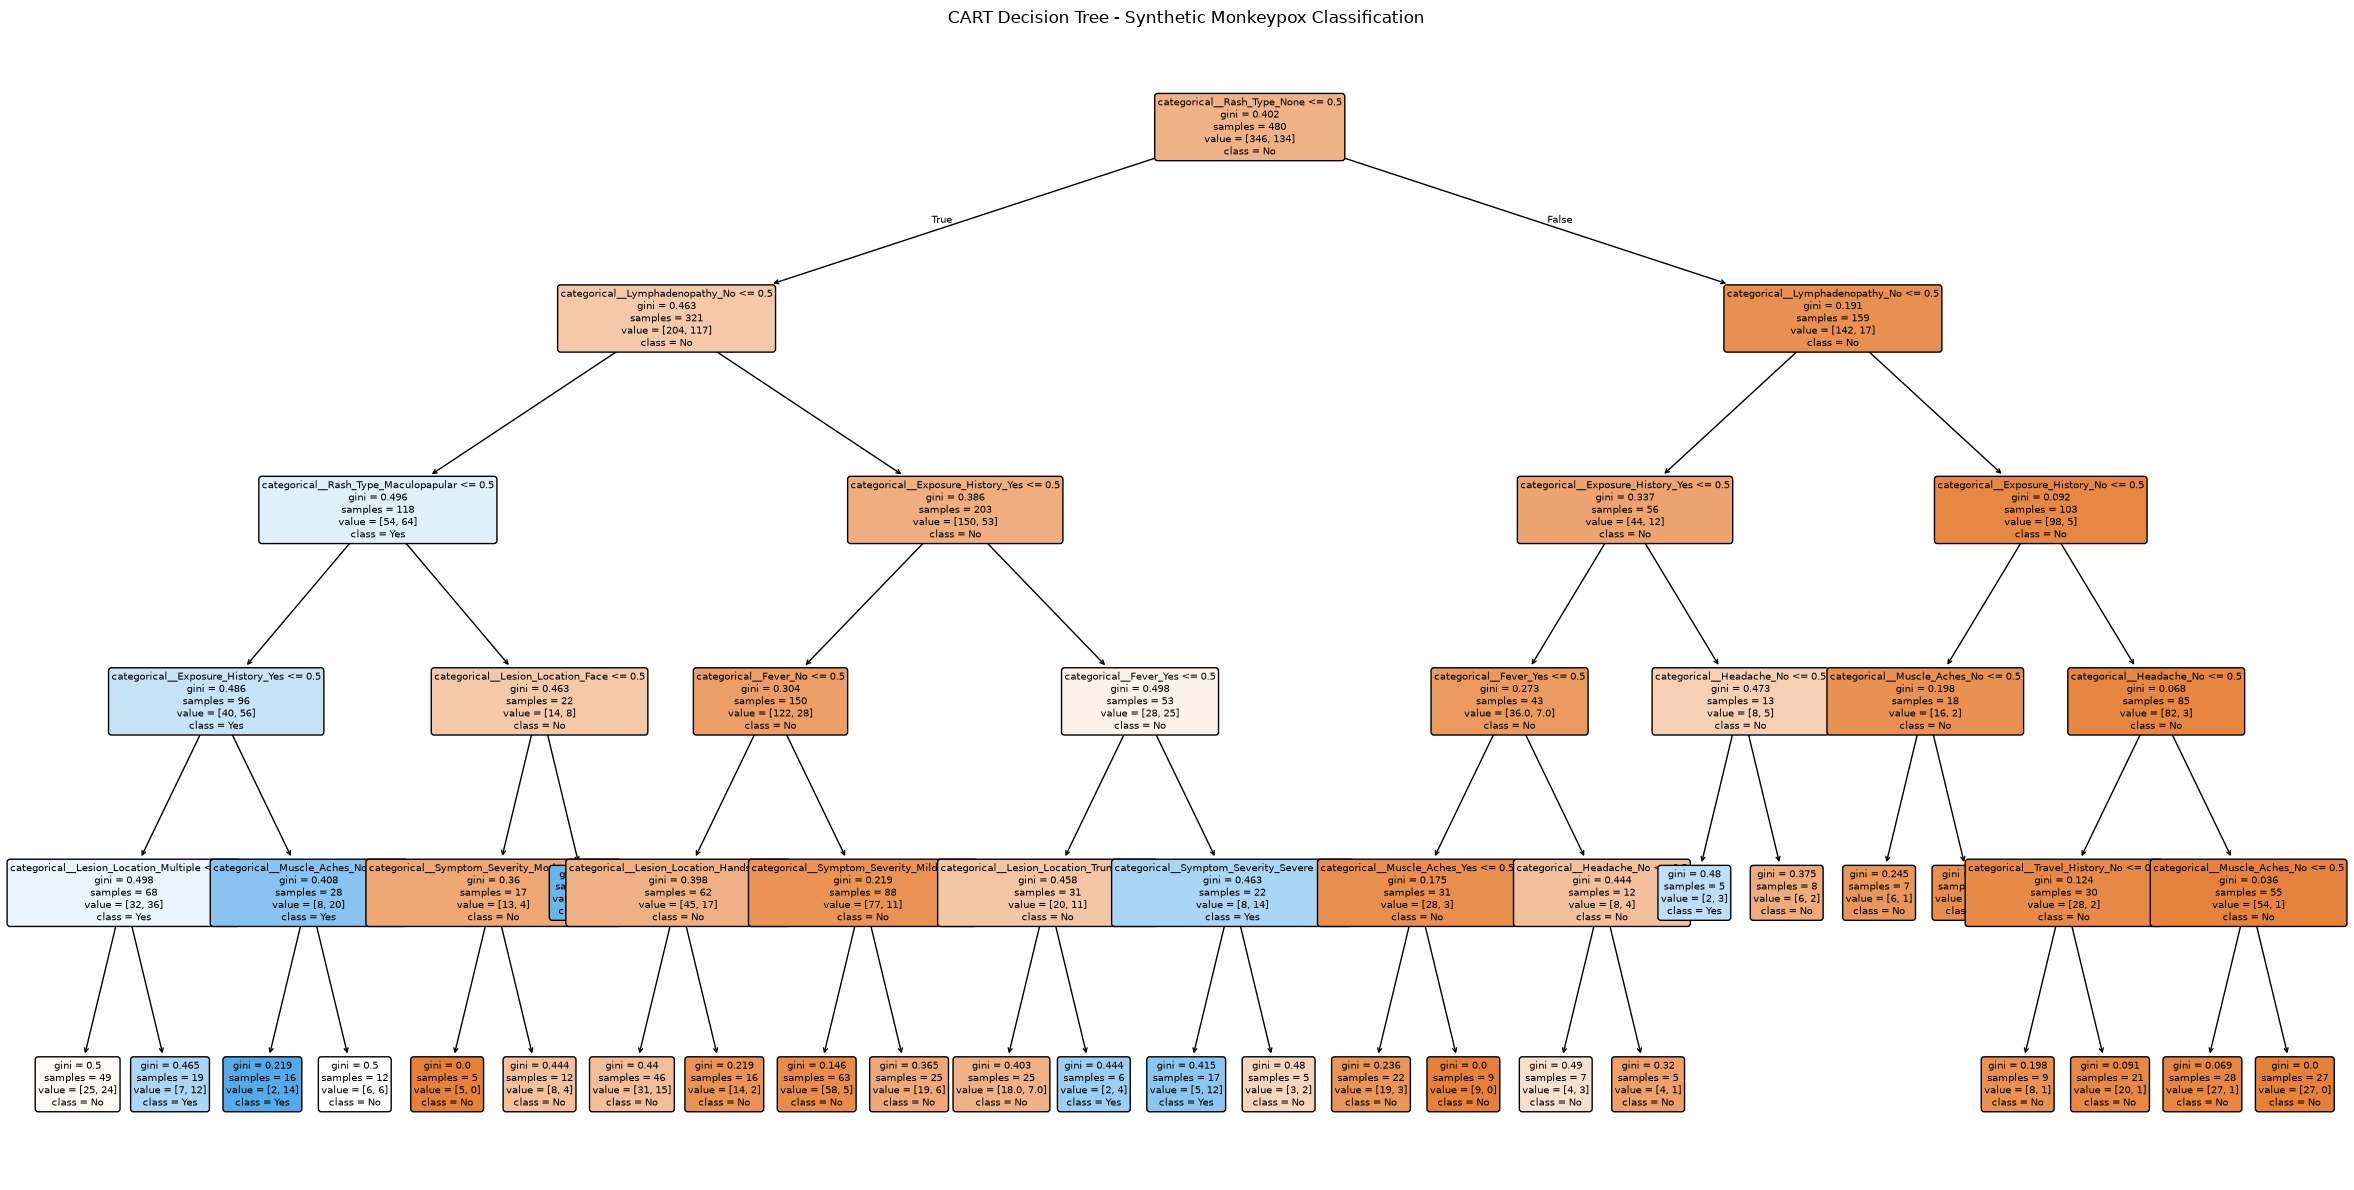

In [18]:
fitted_preprocessor = cart_model.named_steps["preprocessing"]
fitted_tree = cart_model.named_steps["classifier"]

encoded_feature_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))
plot_tree(
    fitted_tree,
    feature_names=encoded_feature_names,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("CART Decision Tree - Synthetic Monkeypox Classification")
plt.tight_layout()
plt.show()

## 19. Feature importance

The decision tree provides importance values for the encoded columns. We aggregate these values back to their original input feature names for easier interpretation.

,Aggregated Importance
Rash,0.2910
Rash_Type,0.2910
Lymphadenopathy,0.2536
Exposure_History,0.1630
Lesion_Location,0.0996
Fever,0.0850
Symptom_Severity,0.0447
Muscle_Aches,0.0409
Headache,0.0211
Travel_History,0.0009


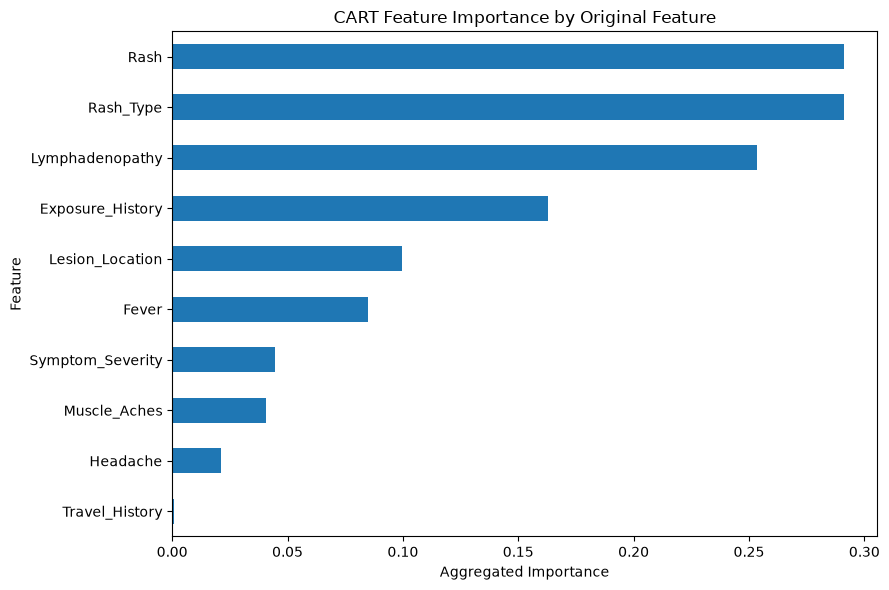

In [19]:
encoded_importance = pd.Series(
    fitted_tree.feature_importances_,
    index=encoded_feature_names
)

original_importance = {}
for original_feature in feature_columns:
    matching = [
        value for encoded_name, value in encoded_importance.items()
        if encoded_name.startswith(f"categorical__{original_feature}_")
    ]
    original_importance[original_feature] = float(sum(matching))

importance = pd.Series(original_importance).sort_values(ascending=False)

display(importance.to_frame("Aggregated Importance").round(4))

plt.figure(figsize=(9, 6))
importance.sort_values().plot(kind="barh")
plt.title("CART Feature Importance by Original Feature")
plt.xlabel("Aggregated Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 20. Predict for a new synthetic example

This demonstrates the mechanics of calling the trained model with a new row. The result is only a prediction from an artificial teaching dataset and has no clinical meaning.

In [20]:
new_example = pd.DataFrame([{
    "Fever": "Yes",
    "Rash": "Yes",
    "Lymphadenopathy": "Yes",
    "Muscle_Aches": "Yes",
    "Headache": "Yes",
    "Exposure_History": "Yes",
    "Travel_History": "No",
    "Rash_Type": "Vesicular",
    "Lesion_Location": "Hands",
    "Symptom_Severity": "Moderate"
}])

new_prediction = cart_model.predict(new_example)[0]
new_prediction_label = "Yes" if new_prediction == 1 else "No"

print("Predicted synthetic target label:", new_prediction_label)
print("Reminder: This is not a medical diagnosis or clinical prediction.")

Predicted synthetic target label: Yes
Reminder: This is not a medical diagnosis or clinical prediction.


## 21. Save outputs

The dataset is generated at the start of the notebook. This section saves the test predictions and the complete manual Gini table as CSV files.

In [21]:
results.to_csv("monkeypox_cart_test_predictions.csv", index=False)
gini_results_df.to_csv("monkeypox_cart_all_gini_splits.csv", index=False)
ranked_splits.to_csv("monkeypox_cart_ranked_splits.csv", index=False)

print("Saved files:")
print("- monkeypox_synthetic_cart_dataset.csv")
print("- monkeypox_cart_test_predictions.csv")
print("- monkeypox_cart_all_gini_splits.csv")
print("- monkeypox_cart_ranked_splits.csv")

Saved files:
- monkeypox_synthetic_cart_dataset.csv
- monkeypox_cart_test_predictions.csv
- monkeypox_cart_all_gini_splits.csv
- monkeypox_cart_ranked_splits.csv


## 22. Final conclusion

This notebook implemented a complete educational CART classification workflow using a synthetic Monkeypox-related dataset with 600 records.

The notebook:
- Identified all input features and their unique values.
- Counted `Yes`, `No`, and total records.
- Calculated Parent Gini impurity.
- Enumerated every unique, non-redundant binary split for each categorical feature.
- Calculated Left Gini, Right Gini, Weighted Child Gini, and Gini Reduction for every candidate.
- Ranked candidate root splits and identified the best one.
- Trained a Scikit-learn CART classifier using one-hot encoded categorical features.
- Evaluated predictions using accuracy, precision, recall, F1-score, and a confusion matrix.
- Visualized the decision tree and aggregated feature importance.

**Interpretation caution:** Because the data and target labels are synthetic, the learned patterns and evaluation metrics are only useful for demonstrating Python and CART. They do not establish real-world Monkeypox risk factors or diagnostic performance.